# Feature Scaling and Engineering 

## Setup & Load All Datasets

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import (
    MinMaxScaler, StandardScaler, RobustScaler,
    MaxAbsScaler, Normalizer, PowerTransformer
)

sns.set_style("whitegrid")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")


# ---- Load datasets ----
boston = pd.read_csv("../datasets/BostonHousing.csv")
heat   = pd.read_csv("../datasets/global_heat_index.csv")
magic  = pd.read_csv("../datasets/magic04.data", header=None,
                     names=["fLength","fWidth","fSize","fConc","fConc1",
                            "fAsym","fM3Long","fM3Trans","fAlpha","fDist","class"])
bike   = pd.read_csv("../datasets/SeoulBikeData.csv", encoding="latin-1")

for name, df in [("Boston", boston), ("HeatIndex", heat),
                 ("MAGIC04", magic), ("SeoulBike", bike)]:
    print(f"{name:10s} shape={df.shape}  cols={list(df.columns)[:5]}...")

Boston     shape=(506, 14)  cols=['crim', 'zn', 'indus', 'chas', 'nox']...
HeatIndex  shape=(17520, 11)  cols=['Year', 'Month', 'Day', 'Hour', 'Dew Point']...
MAGIC04    shape=(19020, 11)  cols=['fLength', 'fWidth', 'fSize', 'fConc', 'fConc1']...
SeoulBike  shape=(8760, 14)  cols=['Date', 'Rented Bike Count', 'Hour', 'Temperature(°C)', 'Humidity(%)']...


##### Different row counts, different column types (categorical vs numeric), different scales.

##### Why scaling matters: demonstrate on Boston

In [16]:
boston_num = boston.select_dtypes(include=np.number)
stats = boston_num.agg(["min","max","mean","std"]).T
stats["range"] = stats["max"] - stats["min"]
stats.sort_values("range", ascending=False)

,min,max,mean,std,range
tax,187.000,711.000,408.237,168.537,524.000
b,0.320,396.900,356.674,91.295,396.580
zn,0.000,100.000,11.364,23.322,100.000
age,2.900,100.000,68.575,28.149,97.100
crim,0.006,88.976,3.614,8.602,88.970
medv,5.000,50.000,22.533,9.197,45.000
lstat,1.730,37.970,12.653,7.141,36.240
indus,0.460,27.740,11.137,6.860,27.280
rad,1.000,24.000,9.549,8.707,23.000
dis,1.130,12.127,3.795,2.106,10.997


##### Observation: some columns span 0–1, others span 0–1000. Any distance-based model (KNN, K-means, SVM, gradient descent) would be dominated by the wide-range feature.

#### 1.Min-Max Scaling

Question it answers: Where does this value sit between the minimum and maximum?

📐 x' = (x − min) / (max − min) → maps to [0, 1]

Best dataset: Boston RM (rooms) — compact range, no severe outliers.



In [17]:
col = "rm"
x = boston[[col]].values

mm = MinMaxScaler()
x_mm = mm.fit_transform(x)

print(f"before: min={x.min():.2f}  max={x.max():.2f}  mean={x.mean():.2f}")
print(f"after : min={x_mm.min():.2f}  max={x_mm.max():.2f}  mean={x_mm.mean():.2f}")

before: min=3.56  max=8.78  mean=6.28
after : min=0.00  max=1.00  mean=0.52


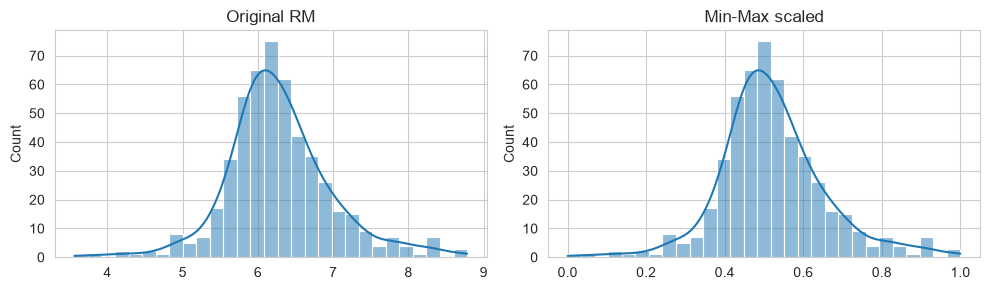

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(10,3))
sns.histplot(x.ravel(),  ax=ax[0], kde=True); ax[0].set_title("Original RM")
sns.histplot(x_mm.ravel(),ax=ax[1], kde=True); ax[1].set_title("Min-Max scaled")
plt.tight_layout(); plt.show()

Observation: \
Shape is identical — only the axis changed. Mean is not 0; it's (mean−min)/(max−min). \
Min-Max Scaling changes the range of the data, but does not change its shape or distribution.

⚠️ Danger: If a new point appears outside training range, it maps outside [0,1]. 

In [19]:
new_point = np.array([[12.0]])       # big room count
print("new value scaled:", mm.transform(new_point))   # > 1

new value scaled: [[1.61697643]]


#### 2.Standardization (Z-score)


Question it answers: How many standard deviations away from the average is this value?

📐 x' = (x − μ) / σ → mean 0, std 1

Best dataset: Boston LSTAT (% lower-status population) — roughly bell-shaped.

In [20]:
col = "lstat"
x = boston[[col]].values

ss = StandardScaler()
x_ss = ss.fit_transform(x)

print(f"mean after={x_ss.mean():.4f}  std after={x_ss.std():.4f}")

mean after=-0.0000  std after=1.0000


In [21]:
# A row with LSTAT = 20 → how many std above mean?
mu, sigma = x.mean(), x.std()
value = 20
z = (value - mu) / sigma
print(f"LSTAT={value} is {z:.2f} std above the mean")

LSTAT=20 is 1.03 std above the mean


When to use: linear models, SVM, PCA, neural nets — anything assuming Gaussian-ish inputs.\
Standardization changes the center and scale.

⚠️ Danger: Standardization is sensitive to outliers (both μ and σ get dragged). Show this:

In [22]:
x_with_outlier = np.append(x, [[100]])
print("mean with outlier:", x_with_outlier.mean(),
      " vs without:", x.mean())

mean with outlier: 12.825345167652861  vs without: 12.653063241106722


What does "Gaussian-ish inputs" mean?

A Gaussian distribution is the familiar bell curve:

``` 
          *
        * * *
      *   *   *
    *     *     *
```

Many real-world features are approximately bell-shaped.

Standardization works especially well when data is roughly Gaussian because:

Mean and standard deviation become meaningful.
Most values fall between -3 and +3.
Optimization algorithms behave better.

But you do not need perfectly normal data to use StandardScaler. It often works well even when the data isn't perfectly Gaussian.

#### 3.Robust Scaling

Question it answers: How far is this value from the median, relative to the middle spread?

📐 x' = (x − median) / IQR

Best dataset: Boston CRIM (crime rate) — long right tail; or Bike Wind speed.

In [23]:
col = "crim"
x = boston[[col]].values

rs = RobustScaler()
x_rs = rs.fit_transform(x)
x_ss = StandardScaler().fit_transform(x)

print("median, IQR:", np.median(x), np.percentile(x,75)-np.percentile(x,25))
print("StandardScaler range:", x_ss.min(), x_ss.max())
print("RobustScaler   range:", x_rs.min(), x_rs.max())

median, IQR: 0.25651 3.5950375
StandardScaler range: -0.4197819386460083 9.933930601860267
RobustScaler   range: -0.06959315445249181 24.678376790228196


Observation: StandardScaler still yields huge positive values (because σ is inflated by the tail). RobustScaler keeps normal points in a tight range and lets the outliers be large — which is exactly what you want.
\
StandardScaler - normal points get compressed ,outlier becomes moderate        
RobustScaler - normal points remain nicely spread, outlier stays obviously extreme


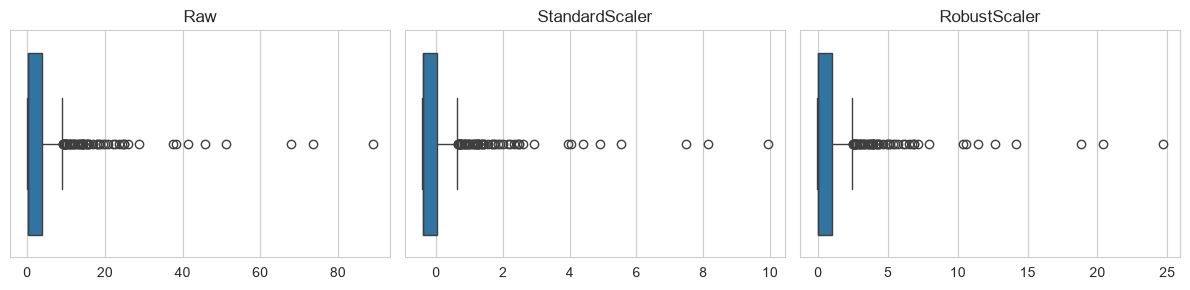

In [24]:
fig, ax = plt.subplots(1,3, figsize=(12,3))
for a, data, t in zip(ax, [x, x_ss, x_rs],
                      ["Raw", "StandardScaler", "RobustScaler"]):
    sns.boxplot(x=data.ravel(), ax=a); a.set_title(t)
plt.tight_layout(); plt.show()

RobustScaler does not try to hide outliers. It scales using the median and IQR so that normal observations remain informative while outliers stay extreme.

#### 4. MaxAbs Scaling

Question it answers: How large is this value compared with the largest absolute value?

📐 x' = x / max(|x|) → range [-1, 1], preserves zero and preserves sparsity.

Best dataset: MAGIC04 fAlpha or fAsym — these can be negative and zero-mean-ish.

In [25]:
col = "fAsym"
x = magic[[col]].values

mas = MaxAbsScaler()
x_mas = mas.fit_transform(x)

print(f"max |x| = {np.abs(x).max():.2f}")
print(f"after: min={x_mas.min():.2f}  max={x_mas.max():.2f}  zeros stay 0: {np.sum(x_mas==0)==np.sum(x==0)}")

max |x| = 575.24
after: min=-0.80  max=1.00  zeros stay 0: True


Why sparsity matters — a quick demo:

In [32]:
import numpy as np
from sklearn.preprocessing import MaxAbsScaler, MinMaxScaler

sparse_like = np.array([[0],
                        [5],
                        [0],
                        [-10],
                        [0]], dtype=float)

print("MaxAbs:")
print(MaxAbsScaler().fit_transform(sparse_like))

print("\nMinMax:")
print(MinMaxScaler().fit_transform(sparse_like))

MaxAbs:
[[ 0. ]
 [ 0.5]
 [ 0. ]
 [-1. ]
 [ 0. ]]

MinMax:
[[0.66666667]
 [1.        ]
 [0.66666667]
 [0.        ]
 [0.66666667]]


Observation: MaxAbs keeps zeros as zeros; MinMax destroys sparsity (0 becomes (0-min)/(max-min)).

#### 5.Vector (L2) Normalization

Question it answers: How do I make each row's vector length = 1?

📐 For each row (not column!): x' = x / ||x||₂

Best dataset: Boston — treat each house's 13 features as a direction vector. Useful for cosine similarity, text-style data.

In [33]:
X = boston.select_dtypes(include=np.number).values

norm = Normalizer(norm="l2")
X_n = norm.fit_transform(X)

print("row norms before:", np.linalg.norm(X[:3], axis=1))
print("row norms after :", np.linalg.norm(X_n[:3], axis=1))

row norms before: [500.62173815 472.55250135 467.20476422]
row norms after : [1. 1. 1.]


Key contrast — column vs row scaling:

In [34]:
print("StandardScaler  → column means:", np.round(X_n.mean(axis=0)[:3],3)) # whatever
print("Normalizer      → row    norms:", np.round(np.linalg.norm(X_n, axis=1)[:3],3))

StandardScaler  → column means: [0.005 0.023 0.019]
Normalizer      → row    norms: [1. 1. 1.]


When to use: cosine similarity, k-NN with cosine metric, TF-IDF-like data, and anytime magnitude is noise and direction is signal.

#### Side-by-side comparison 

Use Boston dis (distance to employment centers — heavily right-skewed with a cap at 12.1):

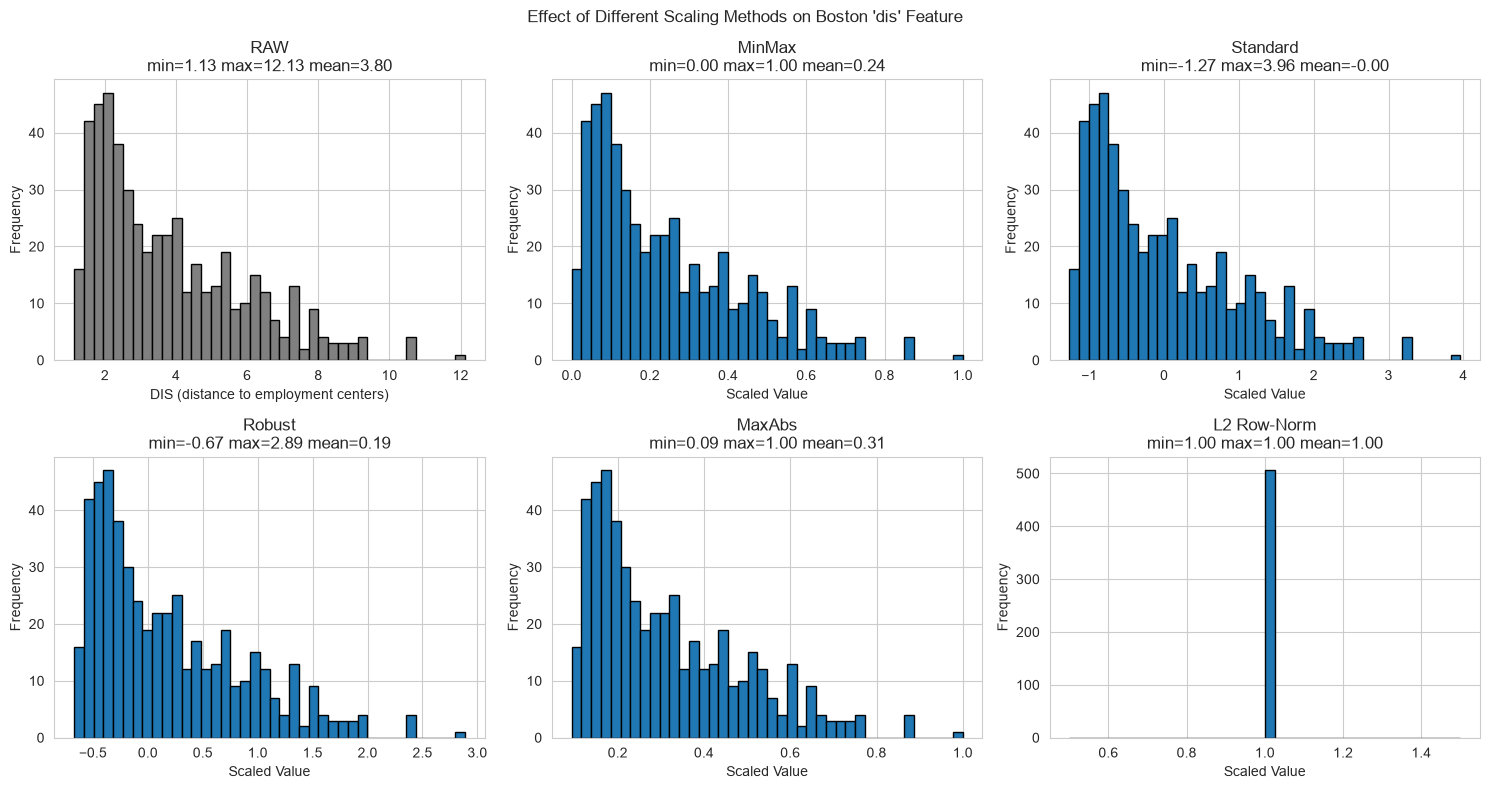

In [36]:
col = "dis"
x = boston[[col]].values

scalers = {
    "MinMax": MinMaxScaler(),
    "Standard": StandardScaler(),
    "Robust": RobustScaler(),
    "MaxAbs": MaxAbsScaler(),
    "L2 Row-Norm": Normalizer(norm="l2"),
}

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

# Raw distribution
axes[0].hist(x.ravel(), bins=40, color="gray", edgecolor="black")
axes[0].set_title(
    f"RAW\nmin={x.min():.2f} max={x.max():.2f} mean={x.mean():.2f}"
)
axes[0].set_xlabel("DIS (distance to employment centers)")
axes[0].set_ylabel("Frequency")

# Scaled distributions
for ax, (name, sc) in zip(axes[1:], scalers.items()):
    xt = sc.fit_transform(x)

    ax.hist(xt.ravel(), bins=40, edgecolor="black")
    ax.set_title(
        f"{name}\nmin={xt.min():.2f} max={xt.max():.2f} mean={xt.mean():.2f}"
    )
    ax.set_xlabel("Scaled Value")
    ax.set_ylabel("Frequency")

plt.suptitle("Effect of Different Scaling Methods on Boston 'dis' Feature")
plt.tight_layout()
plt.show()

For all scalers except L2 Normalizer, the shape should look nearly identical.   
Scaling changes magnitude,
not the ordering of observations. The right-skewed shape remains right-skewed.  
Why L2 norm looks different?    
Normalizer makes no sense for a single positive feature.
It's designed for data like:
```Python
[crim, rm, dis, tax, age]
``` 

MinMax, Standard, Robust, and MaxAbs change the scale of the feature; Normalizer changes each sample, so for a single-column feature it destroys the original distribution.

## Takeaways to Internalize

| Scaler | Range | Mean After Scaling | Robust to Outliers? | Preserves Zero Values? |
|----------|----------|----------|----------|----------|
| **MinMaxScaler** | [0, 1] | ≠ 0 | ❌ No | ❌ No |
| **StandardScaler** | Unbounded | 0 | ❌ No | ❌ No |
| **RobustScaler** | Unbounded* | ≠ 0 (Median = 0) | ✅ Yes | ⚠️ Depends on median |
| **MaxAbsScaler** | [-1, 1] | ≠ 0 | ⚠️ Moderately | ✅ Yes |
| **Normalizer (L2)** | Bounded per row | — | ✅ Per row | ❌ No |

### Notes

- **MinMaxScaler** rescales data to a fixed range (typically `[0, 1]`) but is highly sensitive to outliers.
- **StandardScaler** centers data at mean `0` and standard deviation `1`, but outliers can heavily influence the result.
- **RobustScaler** uses the **median** and **IQR**, making it resistant to outliers.
- **MaxAbsScaler** divides by the maximum absolute value and is useful for sparse datasets because zeros remain zero.
- **Normalizer (L2)** operates on **rows (samples)**, not columns (features). It scales each row so its L2 norm equals 1.

> **\* RobustScaler has median = 0, but mean is not necessarily 0.**
>
> **\* Normalizer is not technically a feature scaler; it normalizes each sample independently.**

#### Where feature engineering comes in?

Scaling is preprocessing. Now let's add columns so scaling actually helps models.

##### a) Log transform on skewed features (Bike: Rented Bike Count)

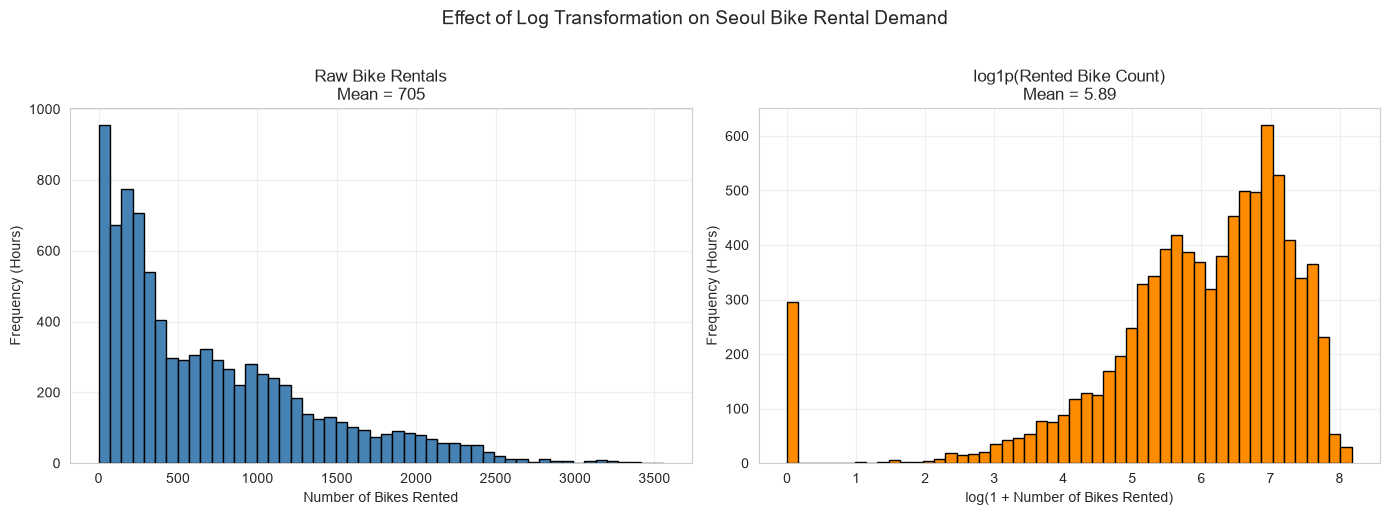

In [39]:
import numpy as np
import matplotlib.pyplot as plt

bike["log_rented"] = np.log1p(bike["Rented Bike Count"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Raw data
axes[0].hist(
    bike["Rented Bike Count"],
    bins=50,
    color="steelblue",
    edgecolor="black"
)
axes[0].set_title(
    f"Raw Bike Rentals\nMean = {bike['Rented Bike Count'].mean():.0f}"
)
axes[0].set_xlabel("Number of Bikes Rented")
axes[0].set_ylabel("Frequency (Hours)")
axes[0].grid(alpha=0.3)

# Log transformed
axes[1].hist(
    bike["log_rented"],
    bins=50,
    color="darkorange",
    edgecolor="black"
)
axes[1].set_title(
    f"log1p(Rented Bike Count)\nMean = {bike['log_rented'].mean():.2f}"
)
axes[1].set_xlabel("log(1 + Number of Bikes Rented)")
axes[1].set_ylabel("Frequency (Hours)")
axes[1].grid(alpha=0.3)

plt.suptitle(
    "Effect of Log Transformation on Seoul Bike Rental Demand",
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.show()

Log transformation doesn't remove outliers; it compresses large values so the distribution becomes less skewed and easier for many ML models to learn.

Combine with scaling afterwards:

In [40]:
bike["rented_scaled"] = StandardScaler().fit_transform(bike[["log_rented"]])

##### b) Date/time engineering (Bike has "Date" as dd/mm/yyyy)

In [41]:
bike["Date"] = pd.to_datetime(bike["Date"], format="%d/%m/%Y")
bike["month"] = bike["Date"].dt.month
bike["dayofweek"] = bike["Date"].dt.dayofweek
bike["is_weekend"] = (bike["dayofweek"] >= 5).astype(int)

# Cyclical encoding — the right way for month
bike["month_sin"] = np.sin(2*np.pi*bike["month"]/12)
bike["month_cos"] = np.cos(2*np.pi*bike["month"]/12)

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_1348\2620726727.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  bike["dayofweek"] = bike["Date"].dt.dayofweek


Key CS concept: cyclical encoding — Dec (12) and Jan (1) should be close, not 11 apart.

##### c) Binning a continuous feature (Boston age)

In [42]:
boston["age_bin"] = pd.cut(boston["age"],
                            bins=[0,25,50,75,100],
                            labels=["new","mid","old","very_old"])
boston["age_bin"].value_counts()

age_bin
very_old    262
mid          98
old          97
new          49
Name: count, dtype: int64

##### d) Interaction feature (Boston: rooms × tax proxy)

In [43]:
boston["rm_x_lstat"] = boston["rm"] * boston["lstat"]
boston[["rm","lstat","rm_x_lstat"]].describe()

,rm,lstat,rm_x_lstat
count,506.000,506.000,506.000
mean,6.285,12.653,76.446
std,0.703,7.141,38.514
min,3.561,1.730,12.956
25%,5.885,6.950,46.347
50%,6.208,11.360,68.182
75%,6.623,16.955,100.532
max,8.780,37.970,201.909


#### e) One-hot encoding (Bike Seasons, Holiday)

In [44]:
bike_enc = pd.get_dummies(bike, columns=["Seasons","Holiday"], drop_first=True)
print(bike_enc.shape)

(8760, 23)


####  The end-to-end mini-pipeline

Put it all together: log-scale → standardize → train a quick model.

In [45]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

bike_clean = bike.copy()
bike_clean["log_target"] = np.log1p(bike_clean["Rented Bike Count"])

num_cols = ["Temperature(°C)", "Humidity(%)", "Wind speed (m/s)",
            "Visibility (10m)", "Solar Radiation (MJ/m2)", "Rainfall(mm)"]
num_cols = [c for c in num_cols if c in bike_clean.columns]

pre = ColumnTransformer([
    ("scale", StandardScaler(), num_cols),
])
X = bike_clean[num_cols]
y = bike_clean["log_target"]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
pipe = Pipeline([("prep", pre), ("model", LinearRegression())])
pipe.fit(X_tr, y_tr)
print("R²:", r2_score(y_te, pipe.predict(X_te)))

R²: 0.2525651649289692



### What we did

1. **Log-transformed the target**
   ```python
   bike_clean["log_target"] = np.log1p(bike_clean["Rented Bike Count"])
   ```
   - Reduced right-skew in bike rental counts.
   - Made extreme rental values less dominant.

2. **Standardized numerical features**
   ```python
   StandardScaler()
   ```
   - Centered features around 0.
   - Scaled features to unit variance.
   - Helps linear models compare features fairly.

3. **Built a preprocessing pipeline**
   ```python
   Pipeline([
       ("prep", pre),
       ("model", LinearRegression())
   ])
   ```
   - Prevents data leakage.
   - Ensures identical preprocessing for train and test data.

4. **Trained a Linear Regression model**
   ```python
   LinearRegression()
   ```
   - Learned the relationship between weather conditions and bike demand.

---

### Model Performance

```text
R² = 0.253
```

Interpretation:

> The model explains about **25.3% of the variation** in bike rental demand using only the selected weather features.

---

### Key Observation

- Log transformation made the target easier to model.
- Standardization put all input features on a comparable scale.
- The pipeline provided a clean, production-style workflow.
- Weather alone explains some demand patterns, but a large portion of rental behavior depends on other factors such as:
  - Hour of day
  - Season
  - Holiday status
  - Functioning day
  - Day of week
  - Special events

---

### Takeaway

✅ **Log-transform skewed targets**

✅ **Standardize numeric features**

✅ **Use a Pipeline to combine preprocessing and modeling**

✅ **Evaluate with R² to measure explained variance**

> A typical machine learning workflow is:
>
> **Clean Data → Transform Target → Scale Features → Train Model → Evaluate Performance**

# Cheat Sheet

| Scenario | Recommended Technique |
|-----------|----------------------|
| Bounded data, no significant outliers, Neural Networks | **MinMaxScaler** |
| Gaussian-ish data, Linear Regression, Logistic Regression, PCA, SVM | **StandardScaler** |
| Data contains many outliers | **RobustScaler** |
| Sparse matrices (TF-IDF, One-Hot Encoded features) | **MaxAbsScaler** |
| Cosine similarity, text embeddings, direction matters more than magnitude | **Normalizer (L2)** |
| Heavy right-skewed distribution | **`log1p()` → then scale** |
| Cyclical features (hour, month, day-of-week, angle) | **sin/cos encoding** |
| Categorical features | **One-Hot Encoding** or **Ordinal Encoding** (only when order is meaningful) |

---

## Quick Memory Tricks

### MinMaxScaler
- Scales to **[0, 1]**
- Preserves shape
- Sensitive to outliers

### StandardScaler
- Mean = **0**
- Std Dev = **1**
- Preferred for many ML algorithms

### RobustScaler
- Median = **0**
- Uses **IQR**
- Resistant to outliers

### MaxAbsScaler
- Scales by maximum absolute value
- Preserves zeros
- Great for sparse data

### Normalizer (L2)
- Scales **rows**, not columns
- Makes each sample have L2 norm = 1
- Common for cosine similarity and NLP

### log1p(x)
- Reduces right-skew
- Handles zeros safely
- Often applied before scaling

### Cyclical Encoding
Instead of:

```python
Hour = 23, 0, 1
```

use:

```python
hour_sin = np.sin(2*np.pi*hour/24)
hour_cos = np.cos(2*np.pi*hour/24)
```

so the model understands that 23:00 and 00:00 are close together.

---

## Common ML Workflow

```text
Raw Data
    ↓
Handle Missing Values
    ↓
Encode Categoricals
    ↓
Fix Skew (log1p if needed)
    ↓
Scale Numerical Features
    ↓
Train Model
    ↓
Evaluate
```

## Exam / Interview Rule

If the algorithm relies on:
- Distance → Scale
- Variance → Scale
- Gradient Descent → Scale

Examples:
- KNN
- K-Means
- SVM
- PCA
- Linear/Logistic Regression
- Neural Networks

If the algorithm is tree-based, scaling is usually unnecessary:
- Decision Tree
- Random Forest
- XGBoost
- LightGBM
- CatBoost